# PredictGuard AI — Phase 1: Image Track
### Casting Defect Classification (Predictive Maintenance Mini Project — Practical 07)



\## Step 0 — Confirm GPU is active

In [ ]:
import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))
print("TensorFlow version:", tf.__version__)

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow version: 2.21.0


## Step 1 — Get the dataset into Colab



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/casting_data.zip"

!unzip -q "{ZIP_PATH}" -d /content/data
print("Unzipped. Contents:")
!ls /content/data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unzipped. Contents:
casting_data  __MACOSX


In [ ]:
DATA_DIR = "/content/data/casting_data"

import os
print("train classes:", os.listdir(os.path.join(DATA_DIR, "train")))
print("test classes:", os.listdir(os.path.join(DATA_DIR, "test")))

train classes: ['.DS_Store', 'ok_front', 'def_front']
test classes: ['.DS_Store', 'ok_front', 'def_front']


## Step 2 — Exploratory Data Analysis



In [ ]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

def count_images(split_dir):
    counts = {}
    for class_dir in sorted(Path(split_dir).iterdir()):
        if class_dir.is_dir():
            counts[class_dir.name] = len(list(class_dir.glob("*.*")))
    return counts

for split in ["train", "test"]:
    split_dir = Path(DATA_DIR) / split
    counts = count_images(split_dir)
    print(f"--- {split.upper()} ---")
    for cls, n in counts.items():
        print(f"  {cls}: {n} images")
    total = sum(counts.values())
    print(f"  TOTAL: {total}")
    if len(counts) == 2:
        vals = list(counts.values())
        ratio = max(vals) / min(vals)
        print(f"  Imbalance ratio: {ratio:.2f}:1\n")

--- TRAIN ---
  def_front: 3758 images
  ok_front: 2875 images
  TOTAL: 6633
  Imbalance ratio: 1.31:1

--- TEST ---
  def_front: 453 images
  ok_front: 262 images
  TOTAL: 715
  Imbalance ratio: 1.73:1



In [ ]:
# Check for corrupt images
def check_corrupt(split_dir):
    corrupt = []
    for class_dir in Path(split_dir).iterdir():
        if not class_dir.is_dir():
            continue
        for img_path in class_dir.glob("*.*"):
            try:
                with Image.open(img_path) as im:
                    im.verify()
            except Exception as e:
                corrupt.append((str(img_path), str(e)))
    return corrupt

train_corrupt = check_corrupt(Path(DATA_DIR) / "train")
test_corrupt = check_corrupt(Path(DATA_DIR) / "test")
print(f"Corrupt in train: {len(train_corrupt)}")
print(f"Corrupt in test: {len(test_corrupt)}")
if train_corrupt:
    print(train_corrupt[:5])

Corrupt in train: 0
Corrupt in test: 0


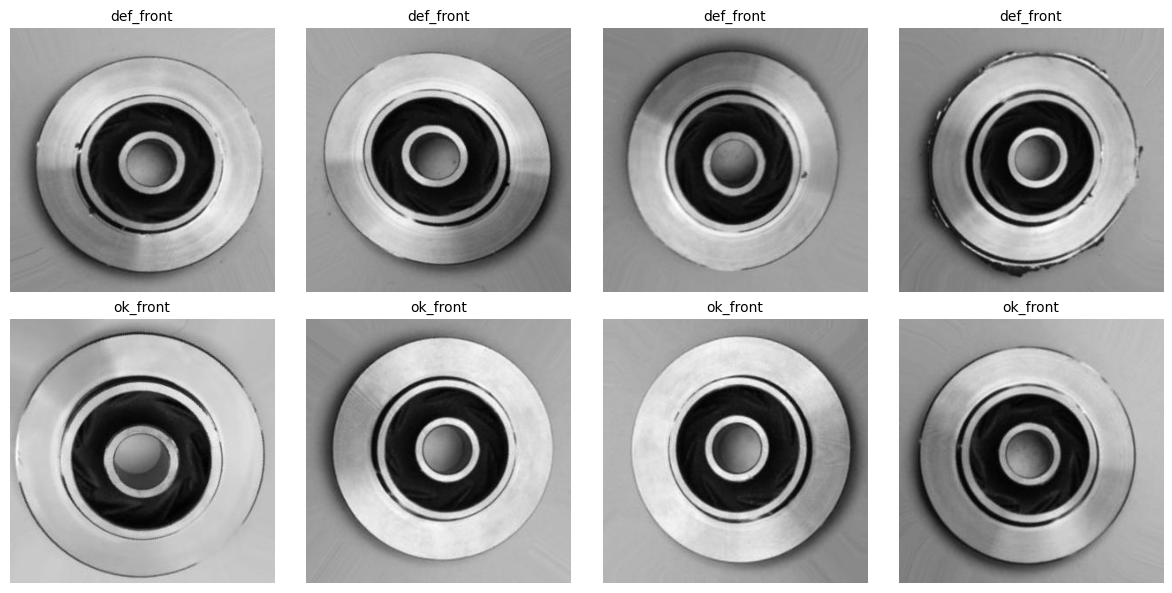

Saved sample_grid.png -- screenshot this for your report


In [ ]:
def show_sample_grid(split_dir, n_per_class=4):
    class_dirs = [d for d in sorted(Path(split_dir).iterdir()) if d.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    for row, class_dir in enumerate(class_dirs):
        img_paths = list(class_dir.glob("*.*"))[:n_per_class]
        for col in range(n_per_class):
            ax = axes[row, col] if len(class_dirs) > 1 else axes[col]
            if col < len(img_paths):
                img = Image.open(img_paths[col])
                ax.imshow(img)
                ax.set_title(class_dir.name, fontsize=10)
            ax.axis("off")
    plt.tight_layout()
    plt.savefig("/content/sample_grid.png", dpi=120)
    plt.show()

show_sample_grid(Path(DATA_DIR) / "train")
print("Saved sample_grid.png -- screenshot this for your report")

In [ ]:
sample_class = next((Path(DATA_DIR) / "train").iterdir())
sample_img = next(sample_class.glob("*.*"))
with Image.open(sample_img) as im:
    print(f"Sample image size: {im.size}, mode: {im.mode}")

StopIteration: 

## Step 3 — Preprocessing: Resize, Normalize, Augment



In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=(0.85, 1.15),
    validation_split=0.15,
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    Path(DATA_DIR) / "train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=42,
)

val_gen = train_datagen.flow_from_directory(
    Path(DATA_DIR) / "train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=42,
)

test_gen = test_datagen.flow_from_directory(
    Path(DATA_DIR) / "test",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False,
)

print("Class indices (label mapping):", train_gen.class_indices)

Found 5639 images belonging to 2 classes.
Found 994 images belonging to 2 classes.
Found 715 images belonging to 2 classes.
Class indices (label mapping): {'def_front': 0, 'ok_front': 1}


In [ ]:
# Preview augmentation effect — screenshot this for your report
preview_gen = ImageDataGenerator(
    rescale=1./255, rotation_range=15, width_shift_range=0.1,
    height_shift_range=0.1, zoom_range=0.15, horizontal_flip=True,
    brightness_range=(0.85, 1.15),
).flow_from_directory(Path(DATA_DIR) / "train", target_size=IMG_SIZE, batch_size=1, class_mode="binary")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    imgs, _ = next(preview_gen)
    ax.imshow(imgs[0])
    ax.axis("off")
fig.suptitle("Augmentation preview")
plt.tight_layout()
plt.savefig("/content/augmentation_preview.png", dpi=120)
plt.show()

## Step 4 — Model Development (Transfer Learning)



In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

base_model = MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=Adam(learning_rate=1e-3), loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

In [ ]:
import os
os.makedirs("/content/models", exist_ok=True)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ModelCheckpoint("/content/models/best_model.h5", monitor="val_accuracy", save_best_only=True),
]

print("Stage 1: training classification head (base frozen)...")
history = model.fit(train_gen, validation_data=val_gen, epochs=10, callbacks=callbacks)

In [ ]:
print("Stage 2: fine-tuning last 20 layers...")
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=1e-5), loss="binary_crossentropy", metrics=["accuracy"])

history_ft = model.fit(train_gen, validation_data=val_gen, epochs=5, callbacks=callbacks)

In [ ]:
# Plot training curves — screenshot for your report
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_ft.history["accuracy"], label="train")
axes[0].plot(history_ft.history["val_accuracy"], label="val")
axes[0].set_title("Accuracy"); axes[0].legend()

axes[1].plot(history_ft.history["loss"], label="train")
axes[1].plot(history_ft.history["val_loss"], label="val")
axes[1].set_title("Loss"); axes[1].legend()

plt.tight_layout()
plt.savefig("/content/training_history.png", dpi=120)
plt.show()

## Step 5 — Evaluation

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
import numpy as np

test_gen.reset()
y_true = test_gen.classes
y_prob = model.predict(test_gen).ravel()
y_pred = (y_prob > 0.5).astype(int)
class_names = list(test_gen.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))
auc = roc_auc_score(y_true, y_prob)
print(f"ROC-AUC: {auc:.4f}")

In [ ]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix — Casting Defect Classifier")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=120)
plt.show()

In [ ]:
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1],[0,1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.tight_layout()
plt.savefig("/content/roc_curve.png", dpi=120)
plt.show()

## Step 6 — Save the Final Model



In [ ]:
FINAL_MODEL_PATH = "/content/models/casting_defect_classifier.h5"
model.save(FINAL_MODEL_PATH)
print("Model saved:", FINAL_MODEL_PATH)

# Copy to Drive so it persists after the session ends
!mkdir -p /content/drive/MyDrive/predictguard-ai/models
!cp {FINAL_MODEL_PATH} /content/drive/MyDrive/predictguard-ai/models/
!cp /content/sample_grid.png /content/augmentation_preview.png /content/training_history.png /content/confusion_matrix.png /content/roc_curve.png /content/drive/MyDrive/predictguard-ai/models/ 2>/dev/null
print("Model and report images copied to Drive: MyDrive/predictguard-ai/models/")



**Next: Phase 2 — Regression on the AI4I 2020 dataset (covers Practical 03).**
Come back to Claude with your results (accuracy / recall numbers, any errors) and we'll continue.
